Assignment 1

f(x,y)=(x-3)^+2+(y+2)^2


Gradient Descent for X:
Iteration 1 (x): x = 0.6000, f(x, y) = 9.7600
Iteration 2 (x): x = 1.0800, f(x, y) = 7.6864
Iteration 3 (x): x = 1.4640, f(x, y) = 6.3593
Iteration 4 (x): x = 1.7712, f(x, y) = 5.5099
Iteration 5 (x): x = 2.0170, f(x, y) = 4.9664
Iteration 6 (x): x = 2.2136, f(x, y) = 4.6185
Iteration 7 (x): x = 2.3709, f(x, y) = 4.3958
Iteration 8 (x): x = 2.4967, f(x, y) = 4.2533
Iteration 9 (x): x = 2.5973, f(x, y) = 4.1621
Iteration 10 (x): x = 2.6779, f(x, y) = 4.1038

Minimum x = 2.6779, f(x, y) = 4.1038


Gradient Descent for Y:
Iteration 1 (y): y = -0.4000, f(x, y) = 11.5600
Iteration 2 (y): y = -0.7200, f(x, y) = 10.6384
Iteration 3 (y): y = -0.9760, f(x, y) = 10.0486
Iteration 4 (y): y = -1.1808, f(x, y) = 9.6711
Iteration 5 (y): y = -1.3446, f(x, y) = 9.4295
Iteration 6 (y): y = -1.4757, f(x, y) = 9.2749
Iteration 7 (y): y = -1.5806, f(x, y) = 9.1759
Iteration 8 (y): y = -1.6645, f(x, y) = 9.1126
Iteration 9 (y): y = -1.7316, f(x, y) = 9.0721
Iteration 10 (y): y = -1.

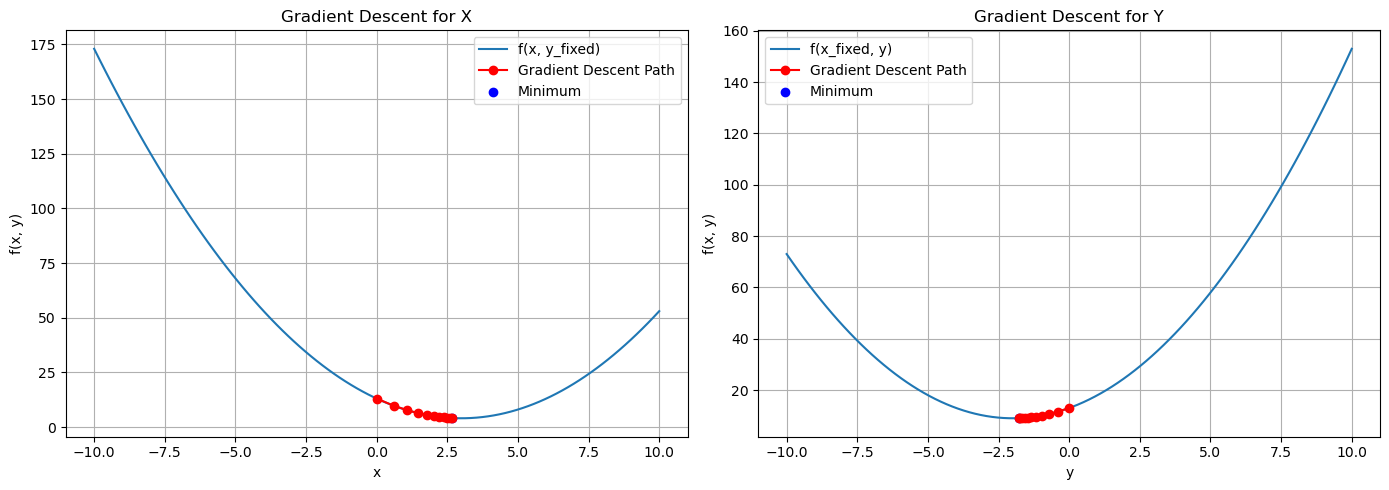

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(x,y):
    return (x-3)**2 + (y+2)**2

def gradient(x, y):
    df_dx = 2*(x-3)
    df_dy = 2*(y+2)
    return df_dx, df_dy

def gradient_descent_x(starting_x, learning_rate, iterations, y_fixed):
    x = starting_x
    path_x = [x]
    for i in range(iterations):
        df_dx, _ = gradient(x, y_fixed)
        x -= learning_rate * df_dx
        path_x.append(x)
        print(f"Iteration {i+1} (x): x = {x:.4f}, f(x, y) = {f(x, y_fixed):.4f}")
    return x, path_x

def gradient_descent_y(starting_y, learning_rate, iterations, x_fixed):
    y = starting_y
    path_y = [y]
    for i in range(iterations):
        _, df_dy = gradient(x_fixed, y)
        y -= learning_rate * df_dy
        path_y.append(y)
        print(f"Iteration {i+1} (y): y = {y:.4f}, f(x, y) = {f(x_fixed, y):.4f}")
    return y, path_y

starting_point = (0, 0)
learning_rate = 0.1
iterations = 10

print("Gradient Descent for X:")
minimum_x, path_x = gradient_descent_x(starting_point[0], learning_rate, iterations, starting_point[1])
print(f"\nMinimum x = {minimum_x:.4f}, f(x, y) = {f(minimum_x, starting_point[1]):.4f}")

print("\n\nGradient Descent for Y:")
minimum_y, path_y = gradient_descent_y(starting_point[1], learning_rate, iterations, starting_point[0])
print(f"\nMinimum y = {minimum_y:.4f}, f(x, y) = {f(starting_point[0], minimum_y):.4f}")

# Create side-by-side plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot for X
x_vals = np.linspace(-10, 10, 100)
Z_x = [(x - 3)**2 + (starting_point[1] + 2)**2 for x in x_vals]
ax1.plot(x_vals, Z_x, label="f(x, y_fixed)")
ax1.plot(path_x, [(x - 3)**2 + (starting_point[1] + 2)**2 for x in path_x], marker="o", color="red", label="Gradient Descent Path")
ax1.scatter(minimum_x, f(minimum_x, starting_point[1]), color="blue", label="Minimum")
ax1.set_xlabel("x")
ax1.set_ylabel("f(x, y)")
ax1.set_title("Gradient Descent for X")
ax1.legend()
ax1.grid()

# Plot for Y
y_vals = np.linspace(-10, 10, 100)
Z_y = [(starting_point[0] - 3)**2 + (y + 2)**2 for y in y_vals]
ax2.plot(y_vals, Z_y, label="f(x_fixed, y)")
ax2.plot(path_y, [(starting_point[0] - 3)**2 + (y + 2)**2 for y in path_y], marker="o", color="red", label="Gradient Descent Path")
ax2.scatter(minimum_y, f(starting_point[0], minimum_y), color="blue", label="Minimum")
ax2.set_xlabel("y")
ax2.set_ylabel("f(x, y)")
ax2.set_title("Gradient Descent for Y")
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()

Question 2: Deep Learning for Image Classification



In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Använder enhet: {device}")


Använder enhet: cuda


In [21]:
transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])  

trainset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transforms)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transforms)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)
classes = trainset.classes

print(f"Antal klasser: {len(classes)}")
print(f"Klasser: {classes}")

100.0%


Antal klasser: 100
Klasser: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 'tulip', 'turtle', 'wardro